In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## roc-curve

**Figure 8: ROC curves for detecting gpt-3.5-turbo text completed by humans on Reddit, with DNA-GPT run on a sliding window.** DNA-GPT splits each text in two and flags it if either half is flagged, while OpenAI and GPTZero classify the whole text; AUC is computed from the plotted curves, markers sit at evenly spaced points along each curve, and the dashed diagonal is chance. DNA-GPT reaches an AUC of 0.987 with the golden prompt and 0.905 without it, against 0.647 for GPTZero and 0.565 for OpenAI.

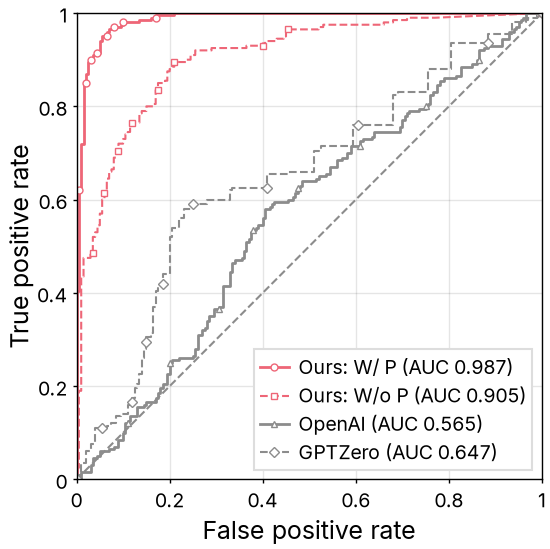

In [2]:
with open("../data/roc-curve.json") as f:
    methods = {m["name"]: m for m in json.load(f)["methods"]}

series = [
    ("Ours: W/ P", "Ours: W/ P", colors["ours"], "-", "o"),
    ("Ours: W/o P", "Ours: W/o P", colors["ours"], "--", "s"),
    ("OpenAI", "OpenAI", colors["neutral"], "-", "^"),
    ("GPTZero", "GPTZero", colors["neutral"], "--", "D"),
]

fig, ax = plt.subplots(figsize=(2.75, 2.75))
for key, name, color, linestyle, marker in series:
    fpr = np.array(methods[key]["fpr"])
    tpr = np.array(methods[key]["tpr"])
    auc = np.trapezoid(tpr, fpr)
    ax.plot(fpr, tpr, color=color, linestyle=linestyle, linewidth=paper.dashed_width if linestyle != "-" else None,
            marker=marker, markevery=np.linspace(0, len(fpr) - 1, 10).astype(int), label=f"{name} (AUC {auc:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=paper.dashed_width, color=colors["neutral"], zorder=1)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ticks = [0, 0.2, 0.4, 0.6, 0.8, 1]
ax.set_xticks(ticks, labels=[f"{t:g}" for t in ticks])
ax.set_yticks(ticks, labels=[f"{t:g}" for t in ticks])
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend(loc="lower right")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/roc-curve.pdf")
fig.savefig("../outputs/roc-curve.png")
plt.show()